# Choosing a Sparse Root Solver

gEconpy provides several solvers for nonlinear systems with sparse Jacobians. All of them run through one
function, `sparse_root`, which takes a solver instance. Below, each solver is configured and compared on standard
test problems, and the notebook ends with perfect foresight simulations of two DSGE models.

The objective function must return a tuple `(residuals, jacobian)`, where the residual is an ndarray
and the Jacobian is a scipy sparse matrix.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

import gEconpy as ge

from gEconpy.plotting import set_matplotlib_style
from gEconpy.solvers.sparse_root import (
    GaussNewtonTrustRegion,
    LevenbergMarquardt,
    SparseDogleg,
    chord,
    inexact_newton_krylov,
    newton_armijo,
    newton_nonmonotone,
    sparse_root,
)
from gEconpy.solvers.sparse_root.direction import ChordDirection, KrylovDirection
from gEconpy.solvers.sparse_root.globalization import ArmijoBacktracking, NonmonotoneBacktracking
from gEconpy.solvers.sparse_root.line_search import LineSearchSolver

set_matplotlib_style()

## Test Problems

We define three test problems. The first is a small system to demonstrate the API. The second, the Broyden
tridiagonal system, is a large sparse system used for most of the comparisons. The third, the trigonometric
system, is small and has a dense Jacobian, but its many near-solutions make it hard for several of the solvers.

In [2]:
def quadratic(x):
    """x^2 - [1, 4] = 0. Solution at [1, 2]."""
    return x**2 - np.array([1.0, 4.0]), sp.diags(2 * x, format="csc")


def broyden_tridiagonal(x):
    """Broyden tridiagonal system. Classic large sparse test problem."""
    n = len(x)
    res = (3.0 - 2.0 * x) * x + 1.0
    res[:-1] -= 2.0 * x[1:]
    res[1:] -= x[:-1]
    jac = sp.diags(
        [-np.ones(n - 1), 3.0 - 4.0 * x, -2 * np.ones(n - 1)],
        [-1, 0, 1],
        format="csc",
    )
    return res, jac


def trigonometric(x):
    """Trigonometric system (More, Garbow, Hillstrom). Many near-solutions."""
    n = len(x)
    sumcos = np.sum(np.cos(x))
    idx = np.arange(1, n + 1, dtype=np.float64)
    res = float(n) - sumcos + idx * (1.0 - np.cos(x)) - np.sin(x)

    diag_vals = (1.0 + idx) * np.sin(x) - np.cos(x)
    off_diag = np.sin(x)
    jac_dense = np.tile(off_diag, (n, 1))
    np.fill_diagonal(jac_dense, diag_vals)
    jac = sp.csc_matrix(jac_dense)
    return res, jac

## Basic Usage

With no solver argument, `sparse_root` defaults to Newton's method with Armijo backtracking {cite:p}`armijo-1966`. This is
a good general-purpose choice.

In [3]:
result = sparse_root(quadratic, np.array([2.0, 3.0]), progressbar=False)
print(f"Success: {result.success}")
print(f"Solution: {result.x}")
print(f"Iterations: {result.nit}")

Success: True
Solution: [1. 2.]
Iterations: 5


To choose a different solver, pass an instance to the `solver` argument.

In [4]:
result = sparse_root(quadratic, np.array([2.0, 3.0]), solver=LevenbergMarquardt(), progressbar=False)
print(f"Success: {result.success}, iterations: {result.nit}")

Success: True, iterations: 5


## The Solvers

The solvers fall into two families.

Line-search solvers compose a direction strategy with a globalization strategy, and factory functions build
them:
- `newton_armijo()`: exact Newton direction with Armijo backtracking
- `chord()`: reuses the Jacobian for several steps, reducing factorization cost
- `inexact_newton_krylov()`: solves the Newton system approximately {cite:p}`dembo-1982` via GMRES {cite:p}`saad-schultz-1986`, good for very large systems
- `newton_nonmonotone()`: Newton direction with a line search that compares against the largest of the last few merit values {cite:p}`grippo-1986`, so the merit function may increase temporarily

Trust-region solvers manage their own step acceptance:
- `SparseDogleg()`: Powell dogleg {cite:p}`powell-1970` within an adaptive trust region
- `GaussNewtonTrustRegion()`: Gauss-Newton with a Steihaug-CG subproblem solver {cite:p}`steihaug-1983`
- `LevenbergMarquardt()`: damped Gauss-Newton with adaptive $\lambda$ {cite:p}`levenberg-1944,marquardt-1963`

Here are all seven on the Broyden tridiagonal system {cite:p}`more-1981` at $n = 1000$.

In [5]:
solvers = {
    "newton_armijo": newton_armijo(),
    "chord": chord(),
    "inexact_newton_krylov": inexact_newton_krylov(),
    "newton_nonmonotone": newton_nonmonotone(),
    "SparseDogleg": SparseDogleg(),
    "GaussNewtonTR": GaussNewtonTrustRegion(),
    "LevenbergMarquardt": LevenbergMarquardt(),
}

n = 1000
x0 = -np.ones(n)

rows = []
for name, solver in solvers.items():
    t0 = time.perf_counter()
    result = sparse_root(broyden_tridiagonal, x0.copy(), solver=solver, progressbar=False)
    elapsed = time.perf_counter() - t0
    rows.append(
        {
            "solver": name,
            "success": result.success,
            "iterations": result.nit,
            "f_evals": result.nfev,
            "max |residual|": f"{np.max(np.abs(result.fun)):.2e}",
            "time (ms)": f"{elapsed * 1000:.1f}",
        }
    )

pd.DataFrame(rows).set_index("solver")

,success,iterations,f_evals,max |residual|,time (ms)
solver,,,,,
newton_armijo,True,5,6,6.66e-16,2.7
chord,True,8,9,4.37e-11,1.7
inexact_newton_krylov,True,7,8,1.22e-15,2.8
newton_nonmonotone,True,5,6,6.66e-16,1.7
SparseDogleg,True,7,8,7.77e-16,2.5
GaussNewtonTR,True,7,8,8.88e-16,2.8
LevenbergMarquardt,True,5,6,2.51e-13,3.4


## Composing Direction and Globalization Strategies

A line-search solver is built from two interchangeable pieces. The direction strategy computes the search
direction at each step, and the globalization strategy chooses how far to step along it.

The factory functions pick defaults for both, but any pair works. Here a Krylov direction (an iterative linear
solve) is paired with a nonmonotone line search:

In [6]:
custom_solver = LineSearchSolver(
    direction=KrylovDirection(krylov_method="gmres"),
    globalization=NonmonotoneBacktracking(memory=10),
)

result = sparse_root(broyden_tridiagonal, -np.ones(1000), solver=custom_solver, progressbar=False)
print(f"Success: {result.success}, iterations: {result.nit}")

Success: True, iterations: 7


## Scaling: Krylov vs Direct Solvers

`newton_armijo` factorizes the Jacobian at every step. `inexact_newton_krylov` solves the Newton system
approximately with GMRES. By default it preconditions GMRES with an LU factorization that it refreshes every 5
directions. `KrylovDirection(recompute_every=None)` turns the factorization off. The plot below times all three on
the Broyden tridiagonal system as $n$ grows. Each solver runs once before timing starts, so the first point does
not include one-time setup.

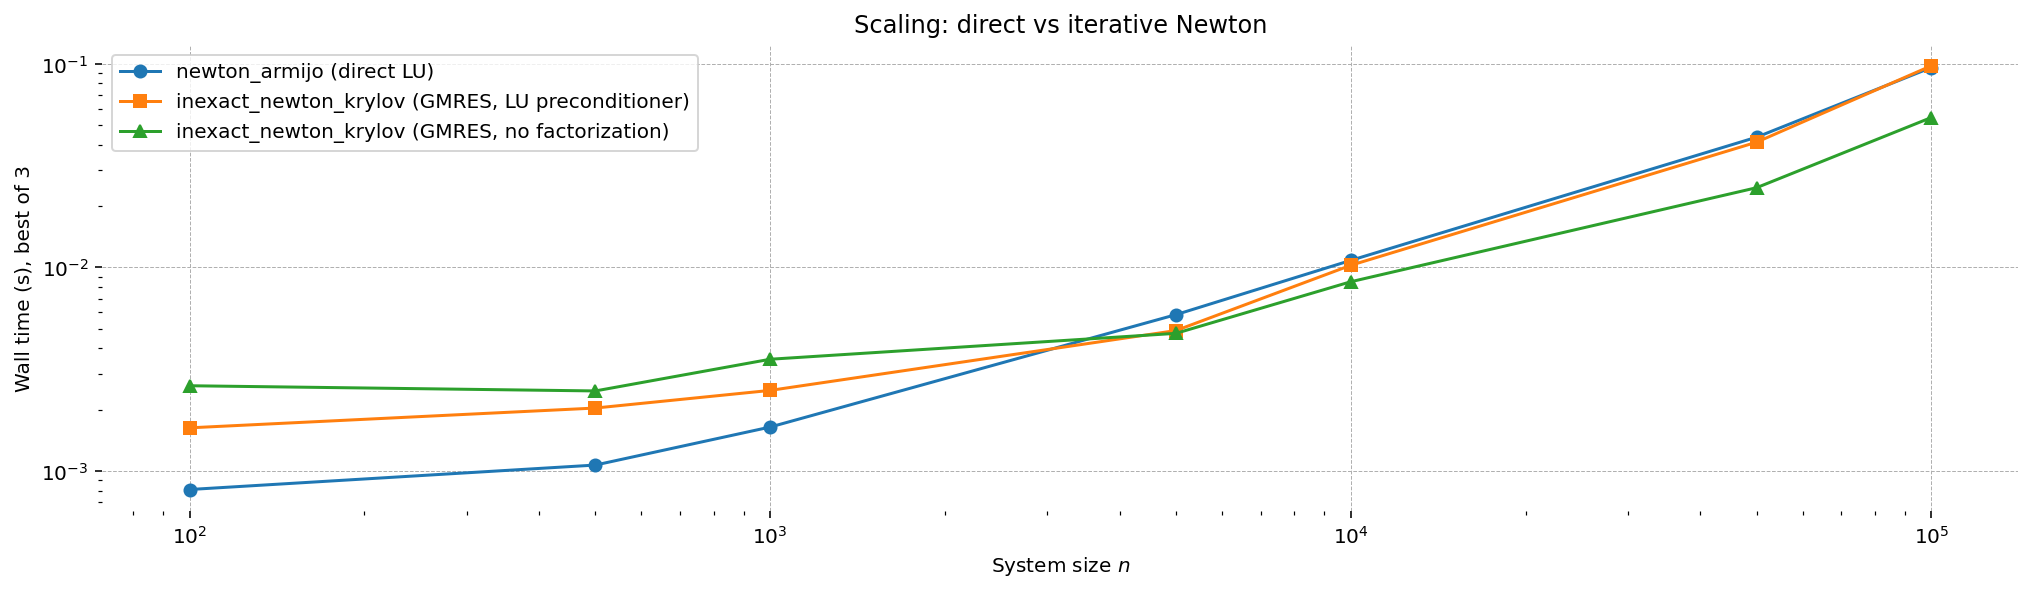

In [7]:
scaling_solvers = {
    "newton_armijo (direct LU)": newton_armijo,
    "inexact_newton_krylov (GMRES, LU preconditioner)": inexact_newton_krylov,
    "inexact_newton_krylov (GMRES, no factorization)": lambda: inexact_newton_krylov(
        direction=KrylovDirection(recompute_every=None)
    ),
}
sizes = [100, 500, 1_000, 5_000, 10_000, 50_000, 100_000]


def best_time(make_solver, n, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        sparse_root(broyden_tridiagonal, -np.ones(n), solver=make_solver(), progressbar=False)
        times.append(time.perf_counter() - t0)
    return min(times)


for make_solver in scaling_solvers.values():
    sparse_root(broyden_tridiagonal, -np.ones(sizes[0]), solver=make_solver(), progressbar=False)

wall_times = {name: [best_time(make_solver, n) for n in sizes] for name, make_solver in scaling_solvers.items()}

fig, ax = plt.subplots()
for (name, times), marker in zip(wall_times.items(), ["o-", "s-", "^-"], strict=True):
    ax.plot(sizes, times, marker, label=name)
ax.set_xlabel("System size $n$")
ax.set_ylabel("Wall time (s), best of 3")
ax.set_title("Scaling: direct vs iterative Newton")
ax.legend()
ax.set_xscale("log")
ax.set_yscale("log")
plt.show()

All three scale linearly, because the LU factorization of a tridiagonal matrix costs $O(n)$. The direct solver is the fastest below a few thousand unknowns. Above that, factorization-free GMRES is faster, taking about half the time of the other two at 100,000 unknowns. The LU-preconditioned default stays close to the direct solver because it pays for the same factorization. `recompute_every=None` is the setting for systems too large to factorize at all.

## Difficult Problems: Trigonometric System

The Moré-Garbow-Hillstrom trigonometric system {cite:p}`more-1981` has many near-solutions. From this starting point
the trust-region solvers stall at one of them, about 0.03 from the root. `inexact_newton_krylov` stalls as well,
while `newton_armijo`, `newton_nonmonotone`, and `chord` converge.

In [8]:
n = 50
x0 = np.ones(n) / n

rows = []
for name, solver in solvers.items():
    result = sparse_root(trigonometric, x0.copy(), solver=solver, progressbar=False, maxiter=500)
    rows.append(
        {
            "solver": name,
            "success": result.success,
            "iterations": result.nit,
            "f_evals": result.nfev,
            "max |residual|": f"{np.max(np.abs(result.fun)):.2e}",
        }
    )

pd.DataFrame(rows).set_index("solver")

,success,iterations,f_evals,max |residual|
solver,,,,
newton_armijo,True,11,38,2.65e-13
chord,True,28,217,5.00e-11
inexact_newton_krylov,False,53,876,1.53e-03
newton_nonmonotone,True,11,36,6.94e-15
SparseDogleg,False,277,331,4.87e-04
GaussNewtonTR,False,34,70,8.48e-04
LevenbergMarquardt,False,31,56,7.00e-04


## Tuning Solver Parameters

Every solver takes its parameters as constructor arguments.

### Chord recompute frequency

The `chord` solver reuses one Jacobian factorization for several steps. Each reused step skips a factorization,
but a stale Jacobian gives a worse direction, so the solver needs more iterations. The `recompute_every`
parameter sets how many steps share a factorization. With `recompute_every=1` it is Newton's method.

In [9]:
rows = []
for freq in [1, 3, 5, 10, 20]:
    solver = chord(direction=ChordDirection(recompute_every=freq))
    result = sparse_root(broyden_tridiagonal, -np.ones(1000), solver=solver, progressbar=False)
    rows.append({"recompute_every": freq, "iterations": result.nit, "success": result.success})

pd.DataFrame(rows).set_index("recompute_every")

,iterations,success
recompute_every,,
1,5,True
3,7,True
5,8,True
10,12,True
20,21,True


Every setting converges. The iteration count grows from 5 with a fresh factorization at every step to 21 when
one factorization serves 20 steps. Whether the trade pays off depends on how much a factorization costs relative to
a function evaluation. For this tridiagonal Jacobian, factorization is cheap.

### Levenberg-Marquardt damping

The initial damping parameter $\lambda_0$ controls how cautious the first steps are. A larger $\lambda_0$
shortens the first steps toward gradient descent, and the solver needs more iterations to shrink the damping back
down.

In [10]:
rows = []
for lam0 in [1e-6, 1e-3, 1.0, 100.0]:
    solver = LevenbergMarquardt(lam0=lam0)
    result = sparse_root(broyden_tridiagonal, -np.ones(1000), solver=solver, progressbar=False)
    rows.append({"lam0": lam0, "iterations": result.nit, "f_evals": result.nfev, "success": result.success})

pd.DataFrame(rows).set_index("lam0")

,iterations,f_evals,success
lam0,,,
0.000001,5,6,True
0.001000,5,6,True
1.000000,8,9,True
100.000000,12,13,True


## Cheap Merit Evaluation with `merit_fun`

During backtracking, the line-search solvers evaluate the objective at every trial step to check the Armijo
condition. By default this calls the full `fun`, which computes the residuals and the Jacobian, although the
Jacobian is only needed at the accepted point.

When the Jacobian is expensive, as in large stacked DSGE systems, that is wasted work. A `merit_fun` passed to
the globalization strategy returns the residuals alone. The solver uses it for every trial evaluation during
backtracking, then calls the full `fun` once at the accepted point to get the Jacobian.

In [11]:
def broyden_residuals_only(x):
    """Residuals of the Broyden tridiagonal system, without the Jacobian."""
    res = (3.0 - 2.0 * x) * x + 1.0
    res[:-1] -= 2.0 * x[1:]
    res[1:] -= x[:-1]
    return res


solver_with_merit = newton_armijo(globalization=ArmijoBacktracking(merit_fun=broyden_residuals_only))

result = sparse_root(broyden_tridiagonal, -np.ones(1000), solver=solver_with_merit, progressbar=False)
print(f"Success: {result.success}, iterations: {result.nit}, f_evals: {result.nfev}")

Success: True, iterations: 5, f_evals: 11


The solver converges in the same 5 iterations as the default. On this problem every first trial step passes the
Armijo test, so there are no rejected points and nothing to save. The count rises from 6 evaluations to 11,
because each accepted step now costs one `merit_fun` call plus one `fun` call. The saving appears when backtracking
rejects trial points, since each rejection then skips a Jacobian. It grows with the size and cost of the Jacobian.
In the perfect foresight simulation below, each Jacobian is a block-tridiagonal sparse matrix assembled across
hundreds of time periods.

## Application: Perfect Foresight Simulation

`ge.solve_perfect_foresight` uses these solvers. A perfect foresight simulation stacks the model equations
across all time periods into one large sparse nonlinear system, whose size grows linearly with the simulation
length.

`solve_perfect_foresight` compiles a residual-only version of the stacked system and attaches it as the
`merit_fun` of the solver's globalization strategy. That happens with the default `newton_armijo` solver and with
any line-search solver you pass that uses `ArmijoBacktracking` or `NonmonotoneBacktracking`, so there is nothing
to set up by hand.

The RBC model below uses the defaults, and the larger New Keynesian model after it uses a custom solver.

### RBC model with defaults

In [12]:
rbc = ge.model_from_gcn(ge.data.get_example_gcn("RBC"), verbose=False)

T = 500
shock = np.zeros(T)
shock[0] = 0.05

trajectory, result = ge.solve_perfect_foresight(
    rbc, simulation_length=T, shocks={"epsilon_A": shock}, sparse_root_kwargs={"progressbar": False}
)
print(f"Success: {result.success}, iterations: {result.nit}")

Success: True, iterations: 3


The system solved here has $T \times n_{\text{vars}}$ unknowns. The table below gives its size and the sparsity of
the Jacobian at the solution.

In [13]:
n_vars = len(rbc.variables)

pd.Series(
    {
        "Variables per period": n_vars,
        "Simulation length": T,
        "Total unknowns": f"{T * n_vars:,}",
        "Jacobian shape": result.jac.shape,
        "Jacobian nonzeros": f"{result.jac.nnz:,}",
        "Density": f"{result.jac.nnz / np.prod(result.jac.shape):.6%}",
    },
    name="RBC",
).to_frame()

,RBC
Variables per period,9
Simulation length,500
Total unknowns,"4,500"
Jacobian shape,"(4500, 4500)"
Jacobian nonzeros,"14,493"
Density,0.071570%


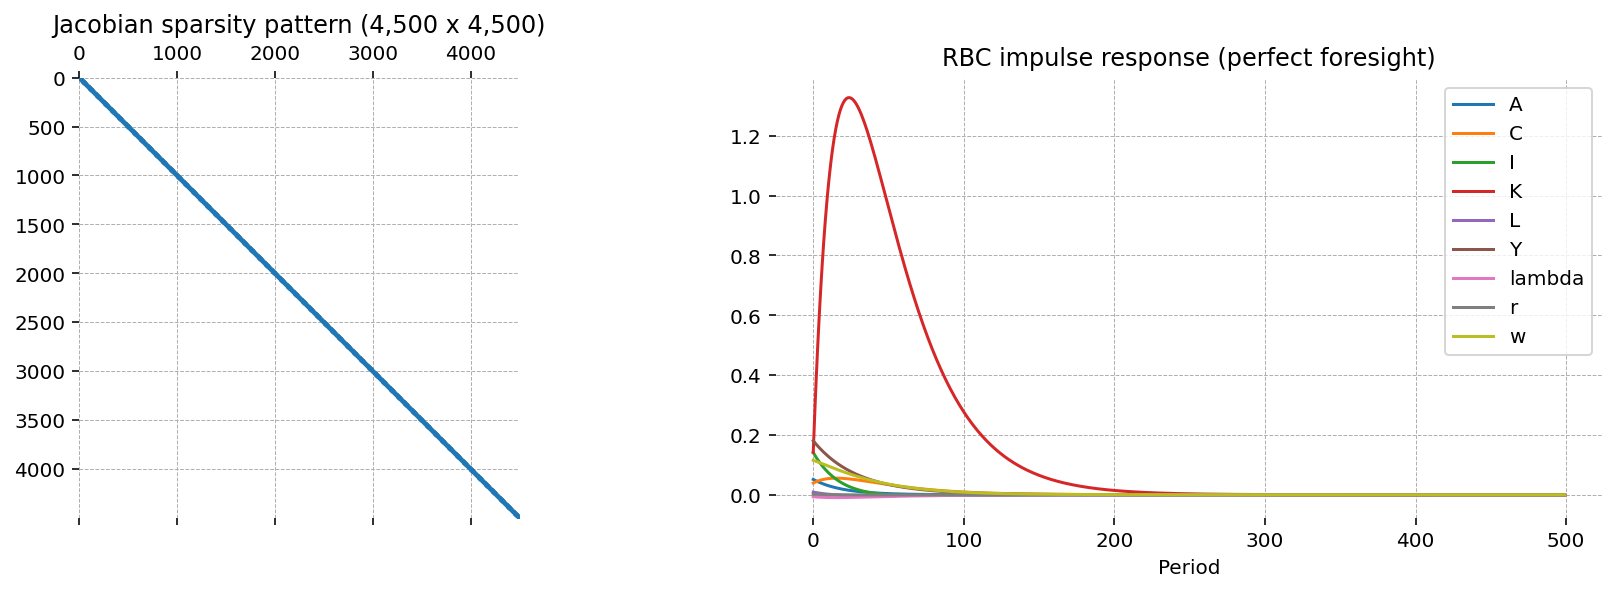

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].spy(result.jac, markersize=0.05)
axes[0].xaxis.set_major_locator(plt.MaxNLocator(nbins=5))
axes[0].set_title(f"Jacobian sparsity pattern ({result.jac.shape[0]:,} x {result.jac.shape[1]:,})")

steady_state = pd.Series({k.removesuffix("_ss"): v for k, v in rbc.steady_state().items()})
(trajectory - steady_state).plot(ax=axes[1], legend=True)
axes[1].set_xlabel("Period")
axes[1].set_title("RBC impulse response (perfect foresight)")
plt.show()

The Jacobian is banded, because each period's equations depend only on variables at $t-1$, $t$, and $t+1$. A
dense factorization of a matrix this size would be far more expensive than the sparse one.

### New Keynesian model with a custom solver

The New Keynesian model has sticky prices, sticky wages, and a monetary policy rule, which give it 23 variables
per period against 9 for the RBC model. Over 300 periods the stacked system has 6,900 unknowns, about 1.5 times
the size of the RBC system above. Any solver can be passed to `solve_perfect_foresight`, and this example uses
`LevenbergMarquardt`, a trust-region solver that adapts its damping parameter $\lambda$ each step.

In [15]:
nk = ge.model_from_gcn(ge.data.get_example_gcn("New_Keynesian"), verbose=False)

T_nk = 300
shock_nk = np.zeros(T_nk)
shock_nk[0] = 0.01

trajectory_nk, result_nk = ge.solve_perfect_foresight(
    nk,
    simulation_length=T_nk,
    shocks={"epsilon_R": shock_nk},
    solver=LevenbergMarquardt(),
    sparse_root_kwargs={"progressbar": False},
)
print(f"Success: {result_nk.success}, iterations: {result_nk.nit}")

Success: True, iterations: 12


In [16]:
n_vars_nk = len(nk.variables)

pd.Series(
    {
        "Variables per period": n_vars_nk,
        "Simulation length": T_nk,
        "Total unknowns": f"{T_nk * n_vars_nk:,}",
        "Jacobian shape": result_nk.jac.shape,
        "Jacobian nonzeros": f"{result_nk.jac.nnz:,}",
        "Density": f"{result_nk.jac.nnz / np.prod(result_nk.jac.shape):.6%}",
    },
    name="New Keynesian",
).to_frame()

,New Keynesian
Variables per period,23
Simulation length,300
Total unknowns,"6,900"
Jacobian shape,"(6900, 6900)"
Jacobian nonzeros,"31,165"
Density,0.065459%


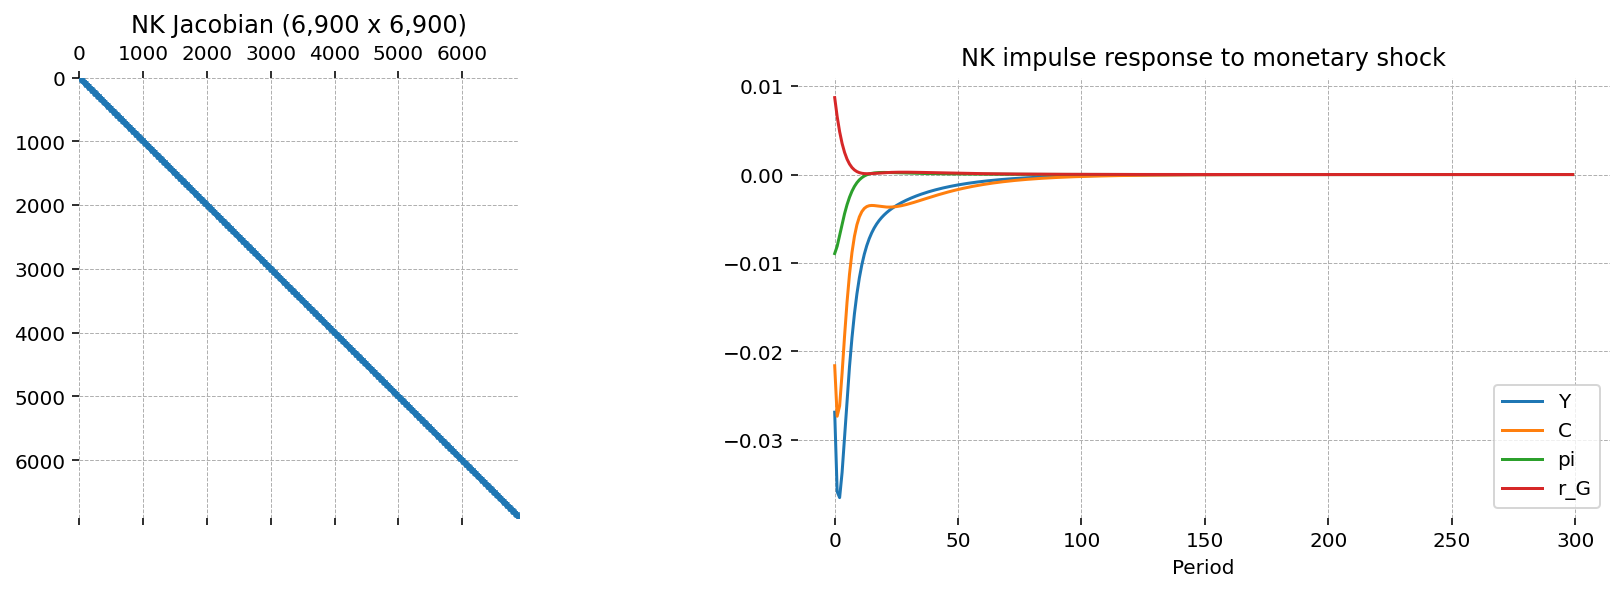

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].spy(result_nk.jac, markersize=0.02)
axes[0].set_title(f"NK Jacobian ({result_nk.jac.shape[0]:,} x {result_nk.jac.shape[1]:,})")

steady_state_nk = pd.Series({k.removesuffix("_ss"): v for k, v in nk.steady_state().items()})

(trajectory_nk - steady_state_nk)[["Y", "C", "pi", "r_G"]].plot(ax=axes[1])
axes[1].set_xlabel("Period")
axes[1].set_title("NK impulse response to monetary shock")
plt.show()

# References

```{bibliography}
```

# Authors

- Authored by Jesse Grabowski in March 2026
- Updated by Jesse Grabowski in September 2026
- Updated by Jesse Grabowski in October 2026


# Watermark

In [18]:
%load_ext watermark
%watermark -n -u -v -iv -w -p gEconpy

Last updated: Sun, 25 Oct 2026

Python implementation: CPython
Python version       : 3.13.13
IPython version      : 9.14.1

gEconpy: 2.2.1.dev2+gaf033cd43

gEconpy   : 2.2.1.dev2+gaf033cd43
matplotlib: 3.10.9
numpy     : 2.4.6
pandas    : 3.0.3
scipy     : 1.18.1

Watermark: 2.6.0

